# What can 100 predictors tell us?
Sebastian Jaramillo · Project 08

My doctoral Problem Sets 9–10 asked four questions with four datasets. This notebook rebuilds the forecasting comparison from the published one-step predictions, inspects how the activity factor changes with data treatment, and checks the conditional interpretation of U.S. hours. The [report](../docs/common_signals.pdf) and [input record](../data/README.md) give sample definitions and source fingerprints.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import Image, display

project = Path.cwd()
if project.name == "notebooks":
    project = project.parent
results = project / "results"

def table(name):
    return pd.read_csv(results / f"{name}.csv")

course = pd.read_csv(project / "data/coursework.csv")
course[["exercise", "quantity", "value"]]

,exercise,quantity,value
0,activity,AR persistence mean,0.825412
1,activity,sales loading mean,0.251055
2,activity,production loading mean,0.371782
3,activity,payroll loading mean,0.496671
4,activity,income loading mean,0.206379
5,wide,OLS RMSE,107.992000
6,wide,Ridge 15 raw RMSE,98.450000
7,wide,PCA 2 RMSE,97.220000
8,hours,1994 impact mean,-0.002411
9,hours,1994 negative impact probability,0.982500


## Did two components still win?
All three class forecasts use four target lags. The two-component model summarizes the 100 other predictors; the two competing methods use all 100. Each forecast uses information through its origin. Only targets 201–300 select the new specification.

In [2]:
validation = table("validation_forecasts").set_index("target")
candidates = table("validation_scores").candidate
validation_rmse = validation[candidates].sub(validation.actual, axis=0).pow(2).mean().pow(0.5)
winner = validation_rmse.idxmin()
assert validation.index.tolist() == list(range(201, 301))
validation_rmse.nsmallest(5).round(3).rename("Validation RMSE").to_frame()

,Validation RMSE
Ridge 500,107.528
Ridge 1500,107.613
Ridge 150,107.880
PCA 2,108.010
Ridge 50,108.332


In [3]:
forecast = table("forecasts").set_index("target")
assert forecast.index.tolist() == list(range(301, 401))
assert np.array_equal(forecast[winner], forecast.Selected)
methods = ["OLS", "Ridge 15 raw", "PCA 2", "Ridge 15", winner, "AR(4)"]
errors = forecast[methods].sub(forecast.actual, axis=0)
scores = pd.DataFrame({"RMSE": errors.pow(2).mean().pow(0.5), "MAE": errors.abs().mean()})
print(f"Reduction against the best class score: {1-scores.loc[winner,'RMSE']/scores.loc['PCA 2','RMSE']:.2%}")
scores.round(3)

Reduction against the best class score: 1.67%


,RMSE,MAE
OLS,107.992,90.087
Ridge 15 raw,98.450,81.101
PCA 2,97.220,78.048
Ridge 15,96.459,77.553
Ridge 500,95.599,76.789
AR(4),143.970,119.215


,PCA 2,Ridge 500
301–350,91.31,90.13
351–400,102.79,100.77


,block,replications,improvement,p025,p975
0,5,5000,1.622,0.188,3.119
1,10,5000,1.622,0.092,3.083


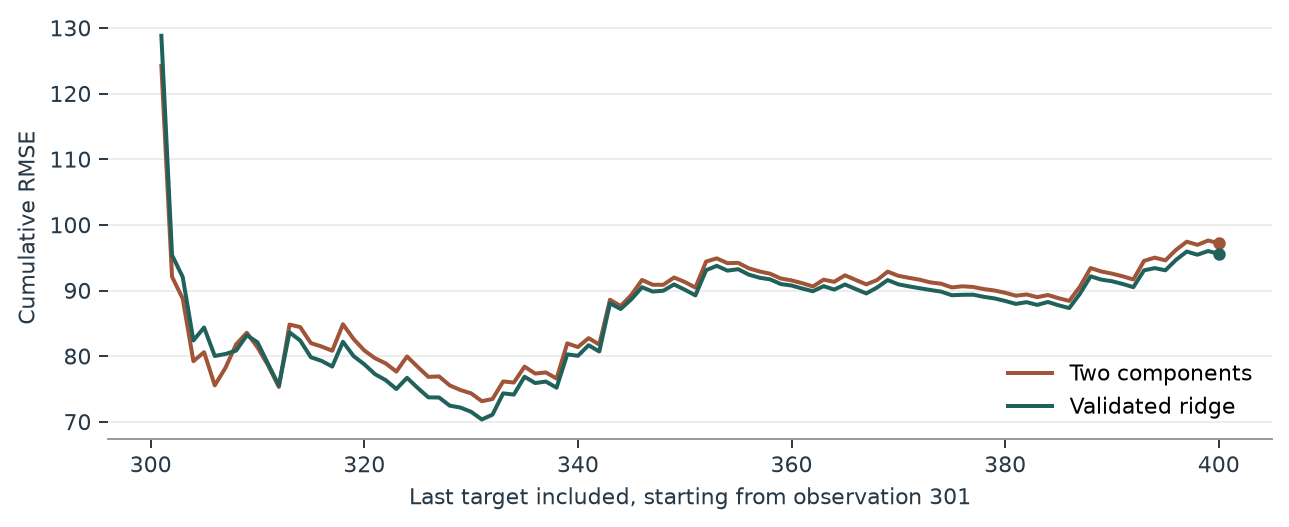

In [4]:
halves = errors[["PCA 2", winner]].pow(2).groupby(np.where(errors.index <= 350, "301–350", "351–400")).mean().pow(0.5)
display(halves.round(2))
display(table("paired_uncertainty").round(3))
display(Image(filename=str(results / "figures/forecast_errors.png"), width=680))

The three benchmarks reproduce their printed scores. Standardizing predictors at the same penalty already helped. Selecting the penalty on earlier data reduced error in both halves of the final sample. The unknown identity of Y limits the economic interpretation of the gain.

## Which indicators move together?
Monthly sales, production, payrolls and income measure related aspects of activity. First compare the original and corrected column treatments with the same seed and sampler. Then compare the full stationary fits, including a sensitivity retaining all observations.

In [5]:
display(table("column_audit").set_index("treatment").round(4))
pars = table("factor_parameters").set_index(["model", "parameter"])
display(pars.xs("phi", level="parameter").round(3))
display(pars.loc["Equities"].filter(like="loading_",axis=0).round(3))
display(table("factor_diagnostics").round(2))

,phi_mean,CMRMTSPL,INDPRO,PAYEMS,W875RX1
treatment,,,,,
Coursework,0.8254,0.2511,0.3718,0.4967,0.2064
Named series,0.8187,0.2582,0.3816,0.5038,0.3225


,mean,p10,median,p90
model,,,,
Coursework,0.825,0.787,0.828,0.867
Named series,0.811,0.774,0.812,0.849
Observed,0.243,0.190,0.243,0.294
Equities,-0.101,-0.121,-0.101,-0.081


,mean,p10,median,p90
parameter,,,,
loading_SPY,0.992,0.978,0.992,1.006
loading_QQQ,0.925,0.911,0.925,0.940
loading_IWM,0.883,0.867,0.882,0.898
loading_DIA,0.951,0.936,0.951,0.965


,model,draws_per_chain,chains,max_rhat,min_bulk,min_tail
0,Named series,3072,4,1.01,539.48,851.98
1,Observed,3072,4,1.00,857.66,1750.56
2,Equities,1536,4,1.01,400.83,874.98


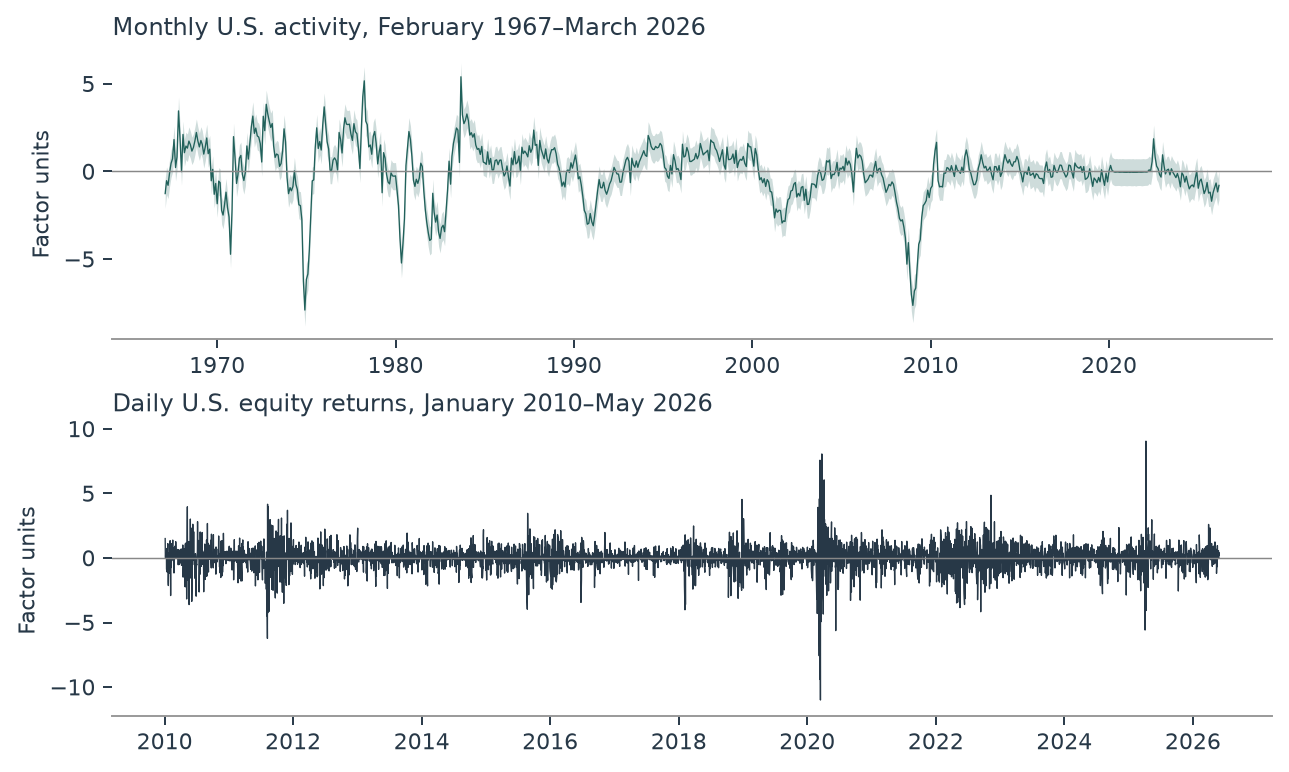

In [6]:
display(Image(filename=str(results / "figures/factor_history.png"), width=690))

The income loading changes when corrections are matched to the right column. Replacing 25 pandemic observations and eight income observations also makes the monthly factor appear more persistent. In the documented equity sample, all four funds have positive loadings even though yesterday's market factor has little persistence. The daily and monthly factor units and time scales differ.

## How did hours respond to a favorable technology shock?
Technology is the shock allowed to change productivity permanently. Responses accumulate quarterly changes starting in the impact quarter. Below, 100 times the log response is approximately the percentage change in hours.

,end,quarter,mean,p10,median,p90,p_negative
0,1994Q3,1,-0.2430,-0.3823,-0.2453,-0.0984,0.9810
11,1994Q3,12,-0.0625,-0.3888,-0.0607,0.2674,0.5956
24,2019Q4,1,-0.2882,-0.3927,-0.2902,-0.1802,0.9988
35,2019Q4,12,-0.3018,-0.6301,-0.2893,0.0151,0.8875


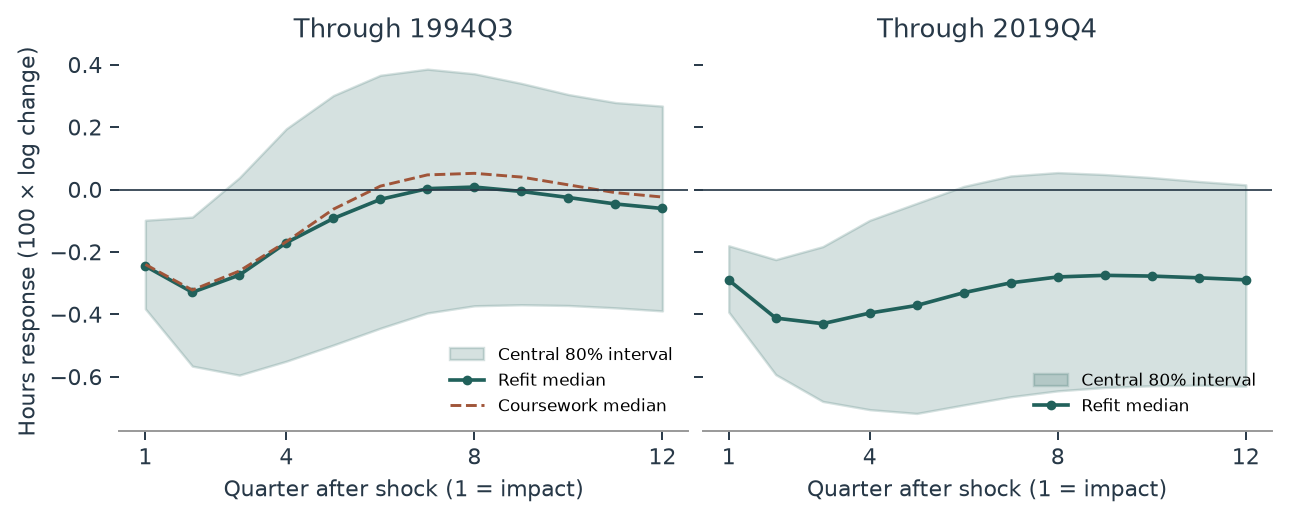

In [7]:
responses = table("hours_responses")
comparison = responses.query("tightness == 0.5 and quarter in [1, 12]").copy()
for col in ["mean","p10","median","p90"]:
    comparison[col] *= 100
display(comparison.drop(columns="tightness").round(4))
display(Image(filename=str(results / "figures/hours_response.png"), width=690))

The earlier refit tracks the archived impact estimate closely. Extending the sample keeps the median hours response negative through the twelfth quarter, but the extended interval at that horizon includes zero. The strongest conclusion concerns the initial response under the long-run restriction. The only measured forecast improvement in these four exercises comes from the indexed prediction panel.